# Demo for DLM-FWI based on Overthrust model
## Description
This notebook implements DLM-FWI using Deepwave and PyTorch.  
It is designed for generating synthetic seismic data, performing wave propagation simulation, and updating velocity models through gradient-based optimization.

## Workflow
1. Import required libraries
2. Load velocity model and acquisition parameters
3. Generate source wavelets and geometry
4. Run forward simulation
5. Compute loss between observed and simulated data
6. Update model parameters
7. Visualize results

## Author
Chao Li

## Date
2026-04-07

In [1]:
import time
import torch
from torchvision import transforms as T, utils
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import io
import hydra
from omegaconf import DictConfig
import os
import sys
import deepwave
from deepwave import scalar
from torch.optim import Adam
from torchaudio.functional import biquad
from scipy.ndimage import gaussian_filter
from scipy.signal import butter
from torch import optim
import sys
from utils.utils import *

In [ ]:
####   MAIN PARAMETERS FOR FORWARD MODELING         ####
####################################################
dx        = 15                  # step interval along x/z direction
dt        = 0.001                # time interval (e.g., 3ms)
num_dims  = 2                     # dimension of velocity model
nz        = 197                  # model shape of z dimension (depth) Marmousi2
ny        = 801                   # model shape of y dimension Marmousi2
vmodel_dim = np.array([nz, ny])

total_t   = 2                      # totle sampling time (unit: s)
nt        = int(total_t / dt)       # number of time sampling points
num_shots = 80                  # nunmber of shots
num_sources_per_shot = 1            # number of sources per shot
num_receivers_per_shot = 800        # number of receivers per shot

source_spacing=10 ###this is the number of grid not the real distance 6:dx*6=90m
receiver_spacing=1 ###this is the number of grid not the real distance 1=15m

source_depth = 0                # the index depth of sources, default is 0
receiver_depth = 0              # the index depths of receivers, default is 0
order          = 8              # precision order of finite difference in space domain
fwi_lr            = 10       # learning rate for updating the model.
fwi_batch         = num_shots     # number of batches for FWI.
fwi_num_epochs    = 100   # number of FWI iteration test
sim_lr            = 1*1e-4    # learning rate for network.
survey_pad = None
savepoch = 50                 # Saving models each 50 FWI iterations
first_source=0
n_sources_per_shot=1
first_receiver=0

Text(0.5, 1.0, 'Initial')

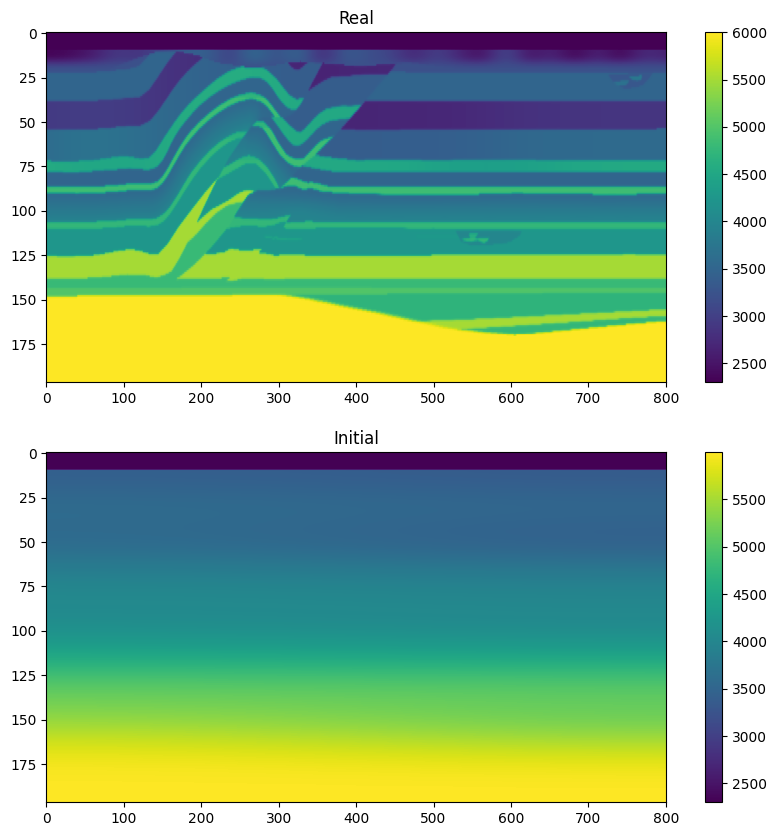

In [3]:
torch.backends.cudnn.enabled = True     ######activate CUDNN
torch.backends.cudnn.benchmark = True   ######select the optimal optimization method

cuda_available = torch.cuda.is_available()
device = torch.device("cuda:0" if cuda_available else "cpu")

directadd=os.path.join(os.getcwd())
data_path = directadd+'/data_overall/myover_197_801.bin'             ####real model
initfile = directadd+'/data_overall/over_vinitbad.mat'       ####initial model
initsafile = directadd+'/data_overall/over_sourceflt.mat'           ####source

fwi_result = directadd+'/results_overall/Over/'

model_true = loadtruemodel(data_path, num_dims, vmodel_dim).to(device)

model, model_init = loadinitmodel(initfile,device)

model = torch.nn.Parameter(model)


plt.figure(figsize=(10,10))
plt.subplot(2,1,1)
plt.imshow(model_true.detach().cpu().numpy(),aspect='auto')
plt.colorbar()
plt.title("Real")
plt.subplot(2,1,2)
plt.imshow(model.detach().cpu().numpy(),aspect='auto')
plt.colorbar()
plt.title("Initial")

In [4]:
source_locations = torch.zeros(
            num_shots, n_sources_per_shot, 2, dtype=torch.long, device=device
        )
source_locations[..., 1] = source_depth

source_locations[:, 0, 0] = torch.arange(num_shots) * source_spacing + first_source

receiver_locations = torch.zeros(
            num_shots, num_receivers_per_shot, 2, dtype=torch.long, device=device
        )
receiver_locations[..., 1] = receiver_depth
receiver_locations[:, :, 0] = (
            (torch.arange(num_receivers_per_shot) * receiver_spacing + first_receiver).repeat(num_shots, 1)
        )

# Setup source amplitudes

source_amplitudes_init, source_amplitudes_true = loadinitsource(initsafile,device)
source_amplitudes_init=source_amplitudes_init.view(nt,1,1)
source = source_amplitudes_init.repeat(1,num_shots, num_sources_per_shot).permute(1,0,2).permute(0,2,1)



Text(0.5, 1.0, 'Shots')

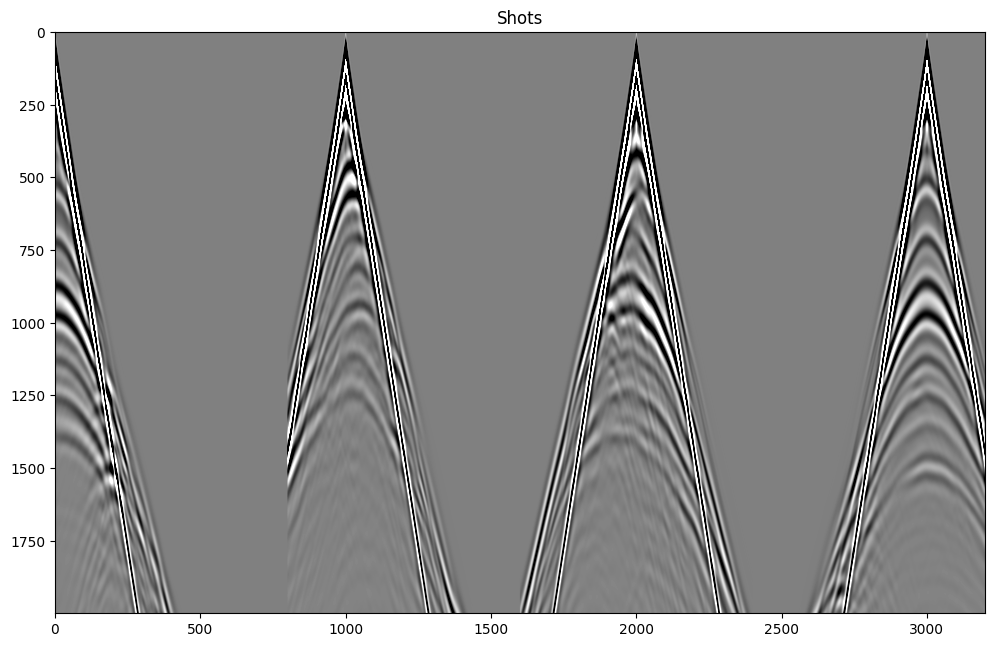

In [5]:
out = deepwave.scalar(model_true.T, dx, dt, source_amplitudes=source,
             source_locations=source_locations,
             receiver_locations=receiver_locations,
             accuracy=8,         
             pml_width=[10,10,10,10]) ################## 

rcv_amps_true = out[-1].permute(2,0,1)

plt.figure(figsize=(12,10))
plt.imshow(rcv_amps_true[:,::20,:].detach().cpu().numpy().reshape(rcv_amps_true[:,::20,:].shape[0],rcv_amps_true[:,::20,:].shape[1]*rcv_amps_true[:,::20,:].shape[2]),cmap='gray',vmin=-1,vmax=1)
plt.title('Shots')

In [6]:
from torchsummary import summary
from Model.network import *

### optimizer for the velocity model
optimizer = optim.Adam([{'params': model, 'lr':fwi_lr, 'betas':(0.5, 0.9), 'eps':1e-8, 'weight_decay':0}])  #####The model here is initial model

leak_value = 0
D1 = 1
netD = Network(D1)
### init the hyper-parameters of netD ###
netD.apply(lambda m: weights_init(m, leak_value))  ###parameter initialization
netD = netD.to(device)

# Optimizer for network.
optim_s = optim.Adam(netD.parameters(),lr=sim_lr,betas=(0.5, 0.9), \
                    eps=1e-8, weight_decay=0)

In [7]:
############## Init  ################# 
SNR = 0.0
SSIM = 0.0
Loss = 0.0
ERROR = 0.0

import torch.nn.functional as F
# Starting the FWI loop

t_start = time.time()


# number of shots per batch
num_shots_per_batch = int(num_shots / fwi_batch)  #####30/30
for i in range(fwi_num_epochs):
    # initialization of the loss
    epoch_loss = 0.0
    for it in range(fwi_batch):
    
        iteration = i*fwi_batch+it+1
        # Set both optimizers to zero grad.
        optimizer.zero_grad()
        netD.train()                
        netD.zero_grad() 
      
        batch_src_amps = source_amplitudes_init.repeat(1, num_shots_per_batch, 1).permute(1,0,2).permute(0,2,1)

        batch_rcv_amps_true = rcv_amps_true[:,it::fwi_batch].to(device)
        

        
        batch_x_s = source_locations[it::fwi_batch].to(device)
        batch_x_r = receiver_locations[it::fwi_batch].to(device)

        

        outpre = deepwave.scalar(model.T, dx, dt, source_amplitudes=batch_src_amps,
             source_locations=batch_x_s,
             receiver_locations=batch_x_r,
             accuracy=8,         
             pml_width=[10,10,10,10])

        batch_rcv_amps_pred = outpre[-1].permute(2,0,1)
       

        batch_rcv_amps_pred = outpre[-1].permute(2,0,1)

        
        
        d_real = (batch_rcv_amps_true).permute(1,0,2)
 
        d_real = d_real.unsqueeze(1)
        
           
      
        d_fake = (batch_rcv_amps_pred).permute(1,0,2)
    
        d_fake = d_fake.unsqueeze(1)


      

        disc_fake, disc_real, o1, o2 = netD(d_fake,d_real)
        # Measure the Eculedian Loss.
    
        if i<=20:
               oo1=o1.clone()
               d_real1=d_real.clone()
               oo1[:,:,1001:2000]=0
               d_real1[:,:,1001:2000]=0
        if i>20 and i<=40:
               oo1=o1.clone()
               d_real1=d_real.clone()
               oo1[:,:,1201:2000]=0
               d_real1[:,:,1201:2000]=0
        if i>40 :
               oo1=o1.clone()
               d_real1=d_real.clone()
               oo1[:,:,1501:2000]=0
               d_real1[:,:,1501:2000]=0


        loss =   F.pairwise_distance(oo1, d_real1, keepdim = True).mean()  
        
       
        epoch_loss += loss.item()
        loss.backward()
        # Updating the network.
        optim_s.step()
        
        # Clips gradient value of model
        torch.nn.utils.clip_grad_value_(model,1e3) 
        

        model.grad[0:10,:]=0 

        optimizer.step()
        # clip the model value that keep the minimum value is larger than 0        
        model.data=torch.clamp(model.data,min=950)     
    


    
    Loss = np.append(Loss, epoch_loss / fwi_batch)

    # compute the SNR and SSIM
    snr = ComputeSNR(model.detach().cpu().numpy(),  
              model_true.detach().cpu().numpy())
    SNR = np.append(SNR, snr)

    ssim = ComputeSSIM(model.detach().cpu().numpy(), \
              model_true.detach().cpu().numpy())
    SSIM = np.append(SSIM, ssim)

    rerror = ComputeRE(model.detach().cpu().numpy(), \
              model_true.detach().cpu().numpy())
    ERROR = np.append(ERROR, rerror)

    print('Epoch:', i+1, 'Loss: ', epoch_loss / fwi_batch, 'SNR:', snr, 'SSIM:', ssim.cpu().detach().cpu().numpy())
   
# Estimating the FWI time
t_end = time.time()
elapsed_time = t_end - t_start
print('Running complete in {:.0f}m  {:.0f}s' .format(elapsed_time //60 , elapsed_time % 60))

Epoch: 1 Loss:  66.71677861213684 SNR: 20.564882 SSIM: 0.2174059
Epoch: 2 Loss:  58.17972860336304 SNR: 20.561361 SSIM: 0.20873669
Epoch: 3 Loss:  49.87951264381409 SNR: 20.554743 SSIM: 0.20282993
Epoch: 4 Loss:  41.4842054605484 SNR: 20.544907 SSIM: 0.197358
Epoch: 5 Loss:  32.0858776807785 SNR: 20.530272 SSIM: 0.19105455
Epoch: 6 Loss:  23.30890085697174 SNR: 20.51449 SSIM: 0.18309744
Epoch: 7 Loss:  16.804619717597962 SNR: 20.494635 SSIM: 0.1727674
Epoch: 8 Loss:  12.37057068347931 SNR: 20.469387 SSIM: 0.16056745
Epoch: 9 Loss:  9.64848833680153 SNR: 20.44119 SSIM: 0.14968361
Epoch: 10 Loss:  8.338571965694427 SNR: 20.412226 SSIM: 0.14219765
Epoch: 11 Loss:  7.563744580745697 SNR: 20.384693 SSIM: 0.13779418
Epoch: 12 Loss:  7.03562548160553 SNR: 20.35902 SSIM: 0.13572809
Epoch: 13 Loss:  6.6497288882732395 SNR: 20.334877 SSIM: 0.13528512
Epoch: 14 Loss:  6.352867192029953 SNR: 20.312016 SSIM: 0.13605395
Epoch: 15 Loss:  6.089442375302315 SNR: 20.290916 SSIM: 0.13782038
Epoch: 16 Los

Text(0.5, 1.0, 'DL')

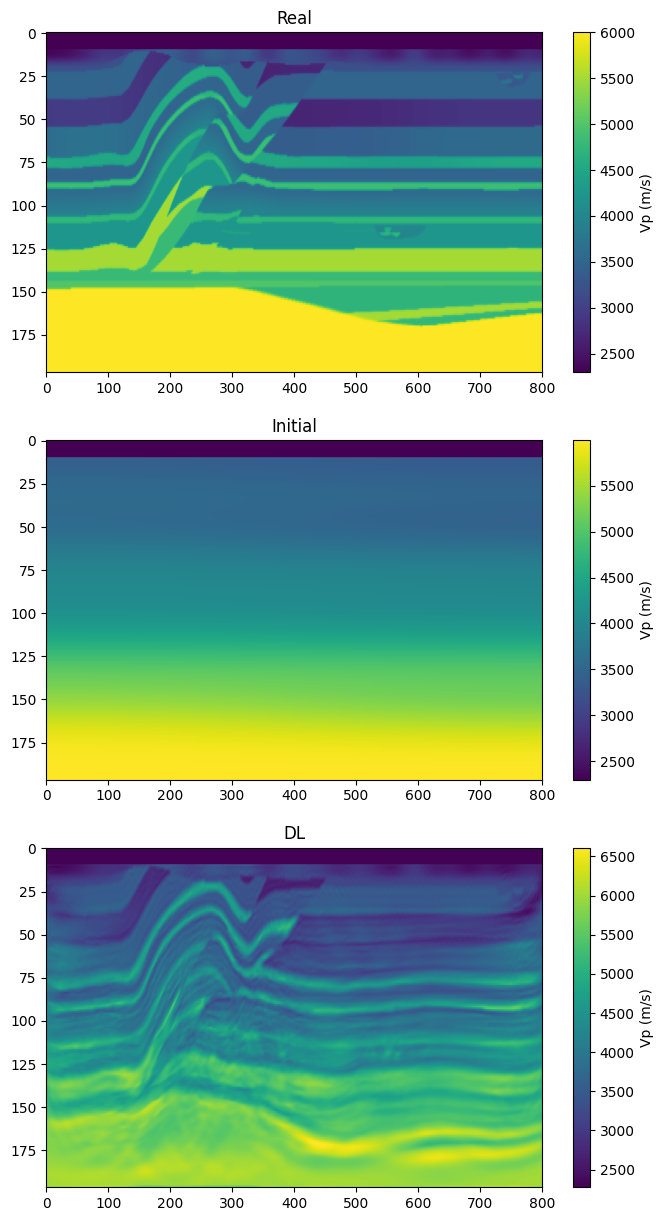

In [8]:
plt.figure(figsize=(8,15))
plt.subplot(3,1,1)
plt.imshow(model_true.detach().cpu().numpy(),aspect='auto')
plt.colorbar(label="Vp (m/s)")
plt.title("Real")
plt.subplot(3,1,2)
plt.imshow(model_init.detach().cpu().numpy(),aspect='auto')
plt.colorbar(label="Vp (m/s)")
plt.title("Initial")
plt.subplot(3,1,3)
plt.imshow(model.detach().cpu().numpy(),aspect='auto')
plt.colorbar(label="Vp (m/s)")
plt.title("DL")